In [1]:
import pandas as pd 
import numpy as np 
import math
import sklearn

In [3]:
df=pd.read_csv("EVChargingStationUsage.csv")
print(df.head())
print(df.shape)

                 Station Name          MAC Address           Org Name  \
0  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
1  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
2  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
3  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   
4  PALO ALTO CA / HAMILTON #1  000D:6F00:015A:9D76  City of Palo Alto   

        Start Date Start Time Zone         End Date End Time Zone  \
0  7/29/2011 20:17             PDT  7/29/2011 23:20           PDT   
1   7/30/2011 0:00             PDT   7/30/2011 0:02           PDT   
2   7/30/2011 8:16             PDT  7/30/2011 12:34           PDT   
3  7/30/2011 14:51             PDT  7/30/2011 16:55           PDT   
4  7/30/2011 18:51             PDT  7/30/2011 20:03           PDT   

  Transaction Date (Pacific Time) Total Duration (hh:mm:ss)  \
0                 7/29/2011 23:20                   3:03:32   
1                  7

/var/folders/v_/70wdhjs53ylbyj_44k3d8p4r0000gn/T/ipykernel_65343/2211134709.py:1: DtypeWarning: Columns (29: User ID, 30: County, 32: Model Number) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("EVChargingStationUsage.csv")


In [5]:
print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))

print("\nExact duplicate rows:", df.duplicated().sum())
display(df.dtypes)


Missing values per column:


County                             84665
EVSE ID                            78948
System S/N                         78948
Model Number                       78948
Driver Postal Code                  8402
User ID                             7677
Currency                            1788
Ended By                             248
Transaction Date (Pacific Time)      209
Port Type                              9
Start Time Zone                        0
Postal Code                            0
Org Name                               0
Start Date                             0
Plug In Event Id                       0
Fee                                    0
Longitude                              0
Latitude                               0
Country                                0
City                                   0
State/Province                         0
End Date                               0
Address 1                              0
MAC Address                            0
Plug Type       


Exact duplicate rows: 4


Station Name                           str
MAC Address                            str
Org Name                               str
Start Date                             str
Start Time Zone                        str
End Date                               str
End Time Zone                          str
Transaction Date (Pacific Time)        str
Total Duration (hh:mm:ss)              str
Charging Time (hh:mm:ss)               str
Energy (kWh)                       float64
GHG Savings (kg)                   float64
Gasoline Savings (gallons)         float64
Port Type                              str
Port Number                          int64
Plug Type                              str
EVSE ID                            float64
Address 1                              str
City                                   str
State/Province                         str
Postal Code                          int64
Country                                str
Latitude                           float64
Longitude  

#### Cleaning Text Columns
Text columns are cleaned by removing leading and trailing whitespace. The Station Name column is further standardized by removinf extra spaces and ensuring consistent formatting around #. This helps avoid duplicate categories caused by formatting differences.

In [6]:
text_cols = ["Station Name", "Port Type", "Plug Type", "Ended By", "Start Time Zone", "End Time Zone"]

for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

df["Station Name"] = (
    df["Station Name"]
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\s*#\s*", " #", regex=True)
)

In [12]:
df["Start Date"] = pd.to_datetime(df["Start Date"], errors="coerce")
df["End Date"] = pd.to_datetime(df["End Date"], errors="coerce")
df["Transaction Date (Pacific Time)"] = pd.to_datetime(df["Transaction Date (Pacific Time)"], errors="coerce")

total_duration = pd.to_timedelta(df["Total Duration (hh:mm:ss)"], errors="coerce")
charging_duration = pd.to_timedelta(df["Charging Time (hh:mm:ss)"], errors="coerce")

In [13]:
numeric_cols = ["Energy (kWh)", "Fee", "Latitude", "Longitude", "GHG Savings (kg)", "Gasoline Savings (gallons)"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [9]:
invalid_time = (
    df["Start Date"].isna() |
    df["End Date"].isna() |
    (df["End Date"] <= df["Start Date"])
)

timestamp_duration_min = (df["End Date"] - df["Start Date"]).dt.total_seconds() / 60
total_duration_min = total_duration.dt.total_seconds() / 60

duration_diff_min = (timestamp_duration_min - total_duration_min).abs()

print("Invalid time rows:", invalid_time.sum())
print("Rows with duration mismatch > 2 min:", (duration_diff_min > 2).sum())
print("Negative energy rows:", (df["Energy (kWh)"] < 0).sum())

Invalid time rows: 83
Rows with duration mismatch > 2 min: 454
Negative energy rows: 0


In [10]:
df = df.drop_duplicates().copy()

clean_mask = (
    df["Start Date"].notna() &
    df["End Date"].notna() &
    (df["End Date"] > df["Start Date"]) &
    df["Station Name"].notna()
)

df_clean = df[clean_mask].copy()

print("Rows after duplicate removal:", len(df))
print("Rows in cleaned dataset:", len(df_clean))

Rows after duplicate removal: 259411
Rows in cleaned dataset: 259328


In [ ]:
quality = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "missing": df_clean.isna().sum(),
    "missing_pct": (df_clean.isna().mean() * 100).round(2)
}).sort_values("missing", ascending=False)

display(quality)

,dtype,missing,missing_pct
County,str,84641,32.64
EVSE ID,float64,78925,30.43
System S/N,float64,78925,30.43
Model Number,str,78925,30.43
Driver Postal Code,float64,8388,3.23
User ID,object,7671,2.96
Currency,str,1787,0.69
Ended By,string,247,0.10
Transaction Date (Pacific Time),datetime64[us],209,0.08
Port Type,string,1,0.00


In [45]:
# Keep records with valid start and end timestamps
valid_time_mask = (df["Start Date"].notna() & df["End Date"].notna() & (df["End Date"] > df["Start Date"]))
df_time = df.loc[valid_time_mask].copy()
print("Original records:", len(df))
print("Records with valid timestamp order:", len(df_time))
print("Records excluded from time-based analysis:", (~valid_time_mask).sum())

Original records: 259415
Records with valid timestamp order: 259332
Records excluded from time-based analysis: 83


In [46]:
duration_review = df.loc[df["Start Date"].notna() & df["End Date"].notna()& (df["End Date"] > df["Start Date"])
                         & (df["Duration_Difference_Minutes"] > 2)].copy()

print("Records with duration discrepancies:", len(duration_review))

Records with duration discrepancies: 411


In [47]:
# Summarize the duration differences
print(duration_review["Duration_Difference_Minutes"].describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

# Display the 20 largest differences
display(duration_review.sort_values("Duration_Difference_Minutes",ascending=False)[
        ["Station Name","Start Date","End Date","Total Duration (hh:mm:ss)","Energy (kWh)","Duration_Difference_Minutes"]
    ].head(20))

count       411.000000
mean       3742.331590
std       15220.212859
min           2.083333
50%         107.866667
90%        5559.733333
95%       11522.091667
99%      100886.953333
max      118437.850000
Name: Duration_Difference_Minutes, dtype: float64


,Station Name,Start Date,End Date,Total Duration (hh:mm:ss),Energy (kWh),Duration_Difference_Minutes
38666,PALO ALTO CA / MPL #6,2015-06-18 13:01:00,2015-09-08 20:24:00,1:25:09,8.338037,118437.850000
38664,PALO ALTO CA / MPL #5,2015-06-18 12:10:00,2015-09-08 20:21:00,2:18:01,13.213822,118432.983333
38606,PALO ALTO CA / MPL #4,2015-06-17 13:04:00,2015-08-27 09:57:00,0:30:13,2.496953,102022.783333
38609,PALO ALTO CA / MPL #4,2015-06-17 14:24:00,2015-08-27 09:57:00,1:25:51,8.336936,101887.150000
38644,PALO ALTO CA / MPL #4,2015-06-18 06:28:00,2015-08-27 09:57:00,1:25:22,2.630938,100923.633333
38673,PALO ALTO CA / MPL #4,2015-06-18 13:55:00,2015-08-27 09:57:00,0:05:10,0.226734,100556.833333
38674,PALO ALTO CA / MPL #4,2015-06-18 14:13:00,2015-08-27 09:57:00,0:15:18,0.554137,100528.700000
39195,PALO ALTO CA / MPL #4,2015-06-30 13:14:00,2015-08-27 09:57:00,0:20:16,1.184045,83302.733333
2389,PALO ALTO CA / HAMILTON #1,2012-03-27 14:40:00,2012-05-09 12:43:00,22:59:59,0.476540,60423.016667
16244,PALO ALTO CA / HAMILTON #2,2013-10-30 17:28:00,2013-12-06 09:45:00,22:59:59,1.738849,51437.016667


In [48]:

# Count the start/end time-zone combinations
print(
    df.groupby(
        ["Start Time Zone", "End Time Zone"],
        dropna=False
    ).size().reset_index(name="Records")
)


  Start Time Zone End Time Zone  Records
0             PDT           PDT   166732
1             PDT           PST       30
2             PDT           UTC        1
3             PST           PDT       58
4             PST           PST    92563
5             UTC           PDT        1
6             UTC           PST       30


In [52]:

# Find records with zero or negative UTC duration
nonpositive_utc = df[
    df["Elapsed_UTC_Minutes"] <= 0
].copy()

# Select only the important columns
columns_to_show = [
    "Station Name",
    "Start Date",
    "Start Time Zone",
    "End Date",
    "End Time Zone",
    "Total Duration (hh:mm:ss)",
    "Elapsed_UTC_Minutes"
]

# Display as a readable table
display(
    nonpositive_utc[columns_to_show]
    .reset_index(drop=True)
)

print("Number of records to investigate:", len(nonpositive_utc))


,Station Name,Start Date,Start Time Zone,End Date,End Time Zone,Total Duration (hh:mm:ss),Elapsed_UTC_Minutes
0,PALO ALTO CA / BRYANT #2,2011-10-10 15:23:00,PDT,2011-10-10 15:23:00,PDT,4:34:38,0.0
1,PALO ALTO CA / BRYANT #2,2013-10-03 12:21:00,PDT,2013-10-03 12:21:00,PDT,0:38:10,0.0
2,PALO ALTO CA / BRYANT #2,2013-10-03 12:31:00,PDT,2013-10-03 12:31:00,PDT,2:48:15,0.0
3,PALO ALTO CA / BRYANT #2,2013-10-03 12:31:00,PDT,2013-10-03 12:31:00,PDT,0:55:05,0.0
4,PALO ALTO CA / BRYANT #2,2013-10-03 12:41:00,PDT,2013-10-03 12:41:00,PDT,1:11:00,0.0
5,PALO ALTO CA / BRYANT #2,2013-10-03 12:51:00,PDT,2013-10-03 12:51:00,PDT,0:25:55,0.0
6,PALO ALTO CA / BRYANT #2,2013-10-03 13:12:00,PDT,2013-10-03 13:12:00,PDT,2:32:34,0.0
7,PALO ALTO CA / BRYANT #2,2013-10-03 13:32:00,PDT,2013-10-03 13:32:00,PDT,5:11:19,0.0
8,PALO ALTO CA / BRYANT #2,2013-10-03 13:42:00,PDT,2013-10-03 13:42:00,PDT,1:01:34,0.0
9,PALO ALTO CA / BRYANT #2,2013-10-03 13:52:00,PDT,2013-10-03 13:52:00,PDT,8:46:58,0.0


Number of records to investigate: 12


In [53]:

# Step 1: Ensure energy is numeric
df["Energy (kWh)"] = pd.to_numeric(
    df["Energy (kWh)"], errors="coerce"
)

# Step 2: Identify records suitable for initial time-based analysis
time_quality_mask = (
    df["Start_UTC"].notna()
    & df["End_UTC"].notna()
    & (df["Elapsed_UTC_Minutes"] > 0)
    & (df["UTC_Duration_Difference_Minutes"] <= 2)
    & df["Station Name"].notna()
    & df["Energy (kWh)"].notna()
)

# Step 3: Create a separate analysis dataset
df_time_clean = df.loc[time_quality_mask].copy()

# Step 4: Keep the records requiring review separately
df_time_review = df.loc[~time_quality_mask].copy()

# Step 5: Check the results
print("Original records:", len(df))
print("Records for initial time-based analysis:", len(df_time_clean))
print("Records requiring review:", len(df_time_review))

print("\nReview reasons:")
print("Missing UTC timestamps:",
      (df["Start_UTC"].isna() | df["End_UTC"].isna()).sum())
print("Zero or negative elapsed duration:",
      (df["Elapsed_UTC_Minutes"] <= 0).sum())
print("Duration difference over 2 minutes:",
      (df["UTC_Duration_Difference_Minutes"] > 2).sum())


Original records: 259415
Records for initial time-based analysis: 259036
Records requiring review: 379

Review reasons:
Missing UTC timestamps: 40
Zero or negative elapsed duration: 12
Duration difference over 2 minutes: 339


In [54]:

# Create the hour for each charging session's start time
df_time_clean["Hour"] = df_time_clean["Start_UTC"].dt.floor("h")

# Calculate total energy by station and hour
hourly_energy = (
    df_time_clean
    .groupby(["Station Name", "Hour"])["Energy (kWh)"]
    .sum()
    .reset_index()
    .sort_values(["Station Name", "Hour"])
)

# Check the results
print("Hourly observations:", len(hourly_energy))
print("Number of stations:", hourly_energy["Station Name"].nunique())

display(hourly_energy.head(10))


Hourly observations: 234691
Number of stations: 47


,Station Name,Hour,Energy (kWh)
0,PALO ALTO CA / BRYANT # 1,2020-09-06 18:00:00+00:00,5.355
1,PALO ALTO CA / BRYANT # 1,2020-09-07 19:00:00+00:00,5.297
2,PALO ALTO CA / BRYANT # 1,2020-10-13 20:00:00+00:00,4.361
3,PALO ALTO CA / BRYANT # 1,2020-10-14 16:00:00+00:00,42.064
4,PALO ALTO CA / BRYANT # 1,2020-10-17 23:00:00+00:00,5.430
5,PALO ALTO CA / BRYANT # 1,2020-10-18 01:00:00+00:00,10.662
6,PALO ALTO CA / BRYANT # 1,2020-10-18 07:00:00+00:00,2.830
7,PALO ALTO CA / BRYANT # 1,2020-10-19 20:00:00+00:00,1.867
8,PALO ALTO CA / BRYANT # 1,2020-10-20 20:00:00+00:00,6.946
9,PALO ALTO CA / BRYANT # 1,2020-10-21 07:00:00+00:00,1.480


In [55]:

# Select one station to test the process
station_name = hourly_energy["Station Name"].iloc[0]

station_data = (
    hourly_energy[
        hourly_energy["Station Name"] == station_name
    ]
    .set_index("Hour")["Energy (kWh)"]
    .sort_index()
)

# Create a continuous hourly timeline
full_hours = pd.date_range(
    start=station_data.index.min(),
    end=station_data.index.max(),
    freq="h"
)

# Add missing hours as zero recorded energy
station_hourly = station_data.reindex(full_hours, fill_value=0)

print("Station:", station_name)
print("First hour:", station_hourly.index.min())
print("Last hour:", station_hourly.index.max())
print("Total hourly time points:", len(station_hourly))
print("Hours with zero recorded energy:", (station_hourly == 0).sum())

display(station_hourly.head(24).to_frame("Energy (kWh)"))


Station: PALO ALTO CA / BRYANT # 1
First hour: 2020-09-06 18:00:00+00:00
Last hour: 2020-12-25 02:00:00+00:00
Total hourly time points: 2625
Hours with zero recorded energy: 2612


,Energy (kWh)
2020-09-06 18:00:00+00:00,5.355
2020-09-06 19:00:00+00:00,0.000
2020-09-06 20:00:00+00:00,0.000
2020-09-06 21:00:00+00:00,0.000
2020-09-06 22:00:00+00:00,0.000
2020-09-06 23:00:00+00:00,0.000
2020-09-07 00:00:00+00:00,0.000
2020-09-07 01:00:00+00:00,0.000
2020-09-07 02:00:00+00:00,0.000
2020-09-07 03:00:00+00:00,0.000


In [56]:

# Check how many records belong to each station name
station_counts = (
    df_time_clean["Station Name"]
    .value_counts()
    .rename_axis("Station Name")
    .reset_index(name="Session_Count")
)

print("Number of station-name labels:", len(station_counts))

display(station_counts.head(20))

# Check the date range for each station label
station_summary = (
    df_time_clean.groupby("Station Name")
    .agg(
        Sessions=("Energy (kWh)", "size"),
        First_Session=("Start_UTC", "min"),
        Last_Session=("Start_UTC", "max")
    )
    .sort_values("Sessions")
)

display(station_summary.head(15))


Number of station-name labels: 47


,Station Name,Session_Count
0,PALO ALTO CA / HAMILTON #2,23691
1,PALO ALTO CA / HAMILTON #1,14846
2,PALO ALTO CA / WEBSTER #1,14416
3,PALO ALTO CA / BRYANT #2,14305
4,PALO ALTO CA / HIGH #4,13858
5,PALO ALTO CA / BRYANT #1,13397
6,PALO ALTO CA / WEBSTER #2,12660
7,PALO ALTO CA / CAMBRIDGE #1,11160
8,PALO ALTO CA / HIGH #1,10749
9,PALO ALTO CA / WEBSTER #3,10477


,Sessions,First_Session,Last_Session
Station Name,,,
PALO ALTO CA / SHERMAN 11,1,2020-12-29 17:01:00+00:00,2020-12-29 17:01:00+00:00
PALO ALTO CA / SHERMAN 15,1,2020-12-26 21:50:00+00:00,2020-12-26 21:50:00+00:00
PALO ALTO CA / SHERMAN 17,1,2020-12-29 17:03:00+00:00,2020-12-29 17:03:00+00:00
PALO ALTO CA / SHERMAN 5,1,2020-12-26 00:44:00+00:00,2020-12-26 00:44:00+00:00
PALO ALTO CA / SHERMAN 9,1,2020-12-13 20:44:00+00:00,2020-12-13 20:44:00+00:00
PALO ALTO CA / SHERMAN 8,2,2020-12-13 22:35:00+00:00,2020-12-19 04:19:00+00:00
PALO ALTO CA / SHERMAN 14,2,2020-12-18 19:38:00+00:00,2020-12-27 22:34:00+00:00
PALO ALTO CA / SHERMAN 6,3,2020-12-09 22:46:00+00:00,2020-12-31 19:04:00+00:00
PALO ALTO CA / SHERMAN 4,4,2020-12-14 23:10:00+00:00,2020-12-27 19:37:00+00:00


In [57]:

# Create a normalized label for checking only
station_check = df_time_clean[["Station Name"]].drop_duplicates().copy()

station_check["Normalized_Name"] = (
    station_check["Station Name"]
    .str.upper()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\s*#\s*", " #", regex=True)
)

# Find normalized names that correspond to multiple original labels
name_variations = (
    station_check.groupby("Normalized_Name")["Station Name"]
    .agg(list)
    .reset_index(name="Original_Names")
)

name_variations["Number_of_Variations"] = (
    name_variations["Original_Names"].str.len()
)

name_variations = name_variations[
    name_variations["Number_of_Variations"] > 1
]

display(name_variations)


,Normalized_Name,Original_Names,Number_of_Variations
0,PALO ALTO CA / BRYANT #1,"[PALO ALTO CA / BRYANT #1, PALO ALTO CA / BRYA...",2


In [58]:

print(
    df_time_clean[
        df_time_clean["Station Name"].str.contains(
            "BRYANT", case=False, na=False
        )
    ]["Station Name"].value_counts()
)


Station Name
PALO ALTO CA / BRYANT #2     14305
PALO ALTO CA / BRYANT #1     13397
PALO ALTO CA / BRYANT #6      5856
PALO ALTO CA / BRYANT #5      5329
PALO ALTO CA / BRYANT #3      4464
PALO ALTO CA / BRYANT #4      3596
PALO ALTO CA / BRYANT # 1       13
Name: count, dtype: int64


In [59]:

# Correct the confirmed Bryant #1 naming variation
df_time_clean["Station Name"] = (
    df_time_clean["Station Name"]
    .replace({
        "PALO ALTO CA / BRYANT # 1":
        "PALO ALTO CA / BRYANT #1"
    })
)

# Verify the result
print(
    df_time_clean[
        df_time_clean["Station Name"].str.contains(
            "BRYANT", case=False, na=False
        )
    ]["Station Name"].value_counts()
)


Station Name
PALO ALTO CA / BRYANT #2    14305
PALO ALTO CA / BRYANT #1    13410
PALO ALTO CA / BRYANT #6     5856
PALO ALTO CA / BRYANT #5     5329
PALO ALTO CA / BRYANT #3     4464
PALO ALTO CA / BRYANT #4     3596
Name: count, dtype: int64


In [60]:

# Create hourly energy for all stations
df_time_clean["Hour"] = df_time_clean["Start_UTC"].dt.floor("h")

hourly_energy = (
    df_time_clean
    .groupby(["Station Name", "Hour"])["Energy (kWh)"]
    .sum()
    .reset_index()
    .sort_values(["Station Name", "Hour"])
)

# Display overall results
print("Hourly observations:", len(hourly_energy))
print("Number of stations:", hourly_energy["Station Name"].nunique())

# Display the first 50 hourly records
display(hourly_energy.head(50))

# Display a summary for ALL stations
station_summary = (
    hourly_energy
    .groupby("Station Name")
    .agg(
        Hourly_Observations=("Hour", "count"),
        Total_Energy_kWh=("Energy (kWh)", "sum"),
        First_Hour=("Hour", "min"),
        Last_Hour=("Hour", "max")
    )
    .reset_index()
    .sort_values("Total_Energy_kWh", ascending=False)
)

print("\nSummary for all stations:")
display(station_summary)


Hourly observations: 234691
Number of stations: 46


,Station Name,Hour,Energy (kWh)
0,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00+00:00,1.630508
1,PALO ALTO CA / BRYANT #1,2011-10-14 01:00:00+00:00,6.631544
2,PALO ALTO CA / BRYANT #1,2011-10-14 21:00:00+00:00,6.259466
3,PALO ALTO CA / BRYANT #1,2011-10-15 19:00:00+00:00,4.622894
4,PALO ALTO CA / BRYANT #1,2011-10-17 20:00:00+00:00,4.023361
5,PALO ALTO CA / BRYANT #1,2011-10-18 20:00:00+00:00,15.474944
6,PALO ALTO CA / BRYANT #1,2011-10-20 00:00:00+00:00,6.762254
7,PALO ALTO CA / BRYANT #1,2011-10-20 20:00:00+00:00,6.073878
8,PALO ALTO CA / BRYANT #1,2011-10-21 16:00:00+00:00,1.482446
9,PALO ALTO CA / BRYANT #1,2011-10-21 19:00:00+00:00,5.135938



Summary for all stations:


,Station Name,Hourly_Observations,Total_Energy_kWh,First_Hour,Last_Hour
12,PALO ALTO CA / HAMILTON #2,20666,191370.913093,2011-08-02 19:00:00+00:00,2020-11-04 12:00:00+00:00
43,PALO ALTO CA / WEBSTER #1,12343,138899.008993,2015-07-29 20:00:00+00:00,2021-01-01 01:00:00+00:00
44,PALO ALTO CA / WEBSTER #2,10820,125674.023719,2015-07-29 23:00:00+00:00,2020-12-31 01:00:00+00:00
11,PALO ALTO CA / HAMILTON #1,14287,113457.607750,2011-07-30 03:00:00+00:00,2020-11-03 21:00:00+00:00
16,PALO ALTO CA / HIGH #4,12835,111531.307913,2011-09-03 03:00:00+00:00,2020-12-07 00:00:00+00:00
1,PALO ALTO CA / BRYANT #2,13455,106723.143087,2011-10-11 02:00:00+00:00,2020-07-01 20:00:00+00:00
0,PALO ALTO CA / BRYANT #1,12602,102147.681243,2011-10-13 19:00:00+00:00,2020-12-25 02:00:00+00:00
45,PALO ALTO CA / WEBSTER #3,9103,98512.988563,2016-01-14 21:00:00+00:00,2020-12-31 22:00:00+00:00
13,PALO ALTO CA / HIGH #1,9208,98359.504769,2015-07-29 22:00:00+00:00,2020-12-31 17:00:00+00:00
39,PALO ALTO CA / TED THOMPSON #1,8505,91144.395604,2016-01-14 18:00:00+00:00,2020-10-11 17:00:00+00:00


Energy and activity by hour of day:


,Hour_Of_Day,Total_Energy_kWh,Active_Station_Hours
0,0,128181.050497,15531
1,1,144187.108215,16902
2,2,124057.855491,14380
3,3,84188.143986,9325
4,4,65212.446709,5940
5,5,47034.777663,3625
6,6,26916.252887,1838
7,7,12396.197858,745
8,8,4910.734275,296
9,9,2631.348001,163


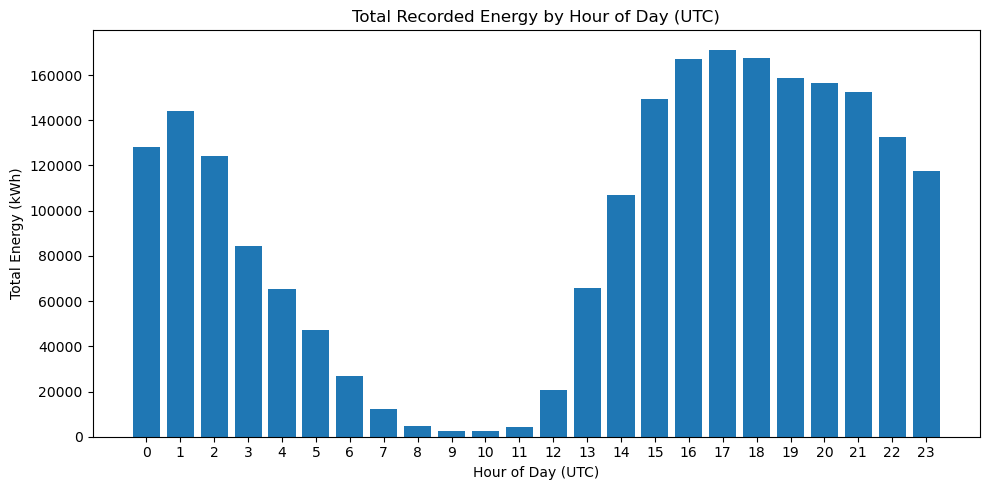

In [61]:

# Extract hour of day from the UTC timestamp
hourly_energy["Hour_Of_Day"] = hourly_energy["Hour"].dt.hour

# Calculate total energy and number of active station-hours for each hour
demand_by_hour = (
    hourly_energy.groupby("Hour_Of_Day")
    .agg(
        Total_Energy_kWh=("Energy (kWh)", "sum"),
        Active_Station_Hours=("Station Name", "count")
    )
    .reset_index()
)

print("Energy and activity by hour of day:")
display(demand_by_hour)

# Plot total energy by hour of day
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(
    demand_by_hour["Hour_Of_Day"],
    demand_by_hour["Total_Energy_kWh"]
)
plt.title("Total Recorded Energy by Hour of Day (UTC)")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Total Energy (kWh)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


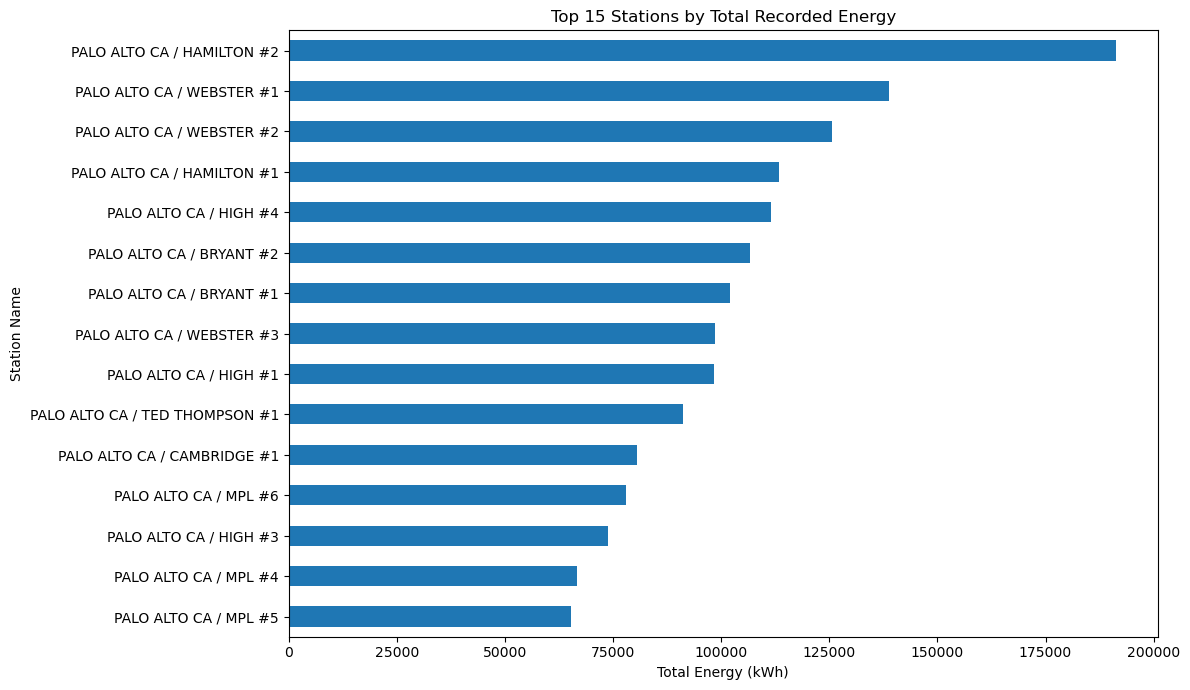

In [62]:

# Calculate total energy for each station
station_energy = (hourly_energy.groupby("Station Name")["Energy (kWh)"].sum().sort_values(ascending=False))

# Select the top 15 stations
top_15 = station_energy.head(15).sort_values()

# Plot with station names
plt.figure(figsize=(12, 7))
top_15.plot(kind="barh")

plt.title("Top 15 Stations by Total Recorded Energy")
plt.xlabel("Total Energy (kWh)")
plt.ylabel("Station Name")
plt.tight_layout()
plt.show()


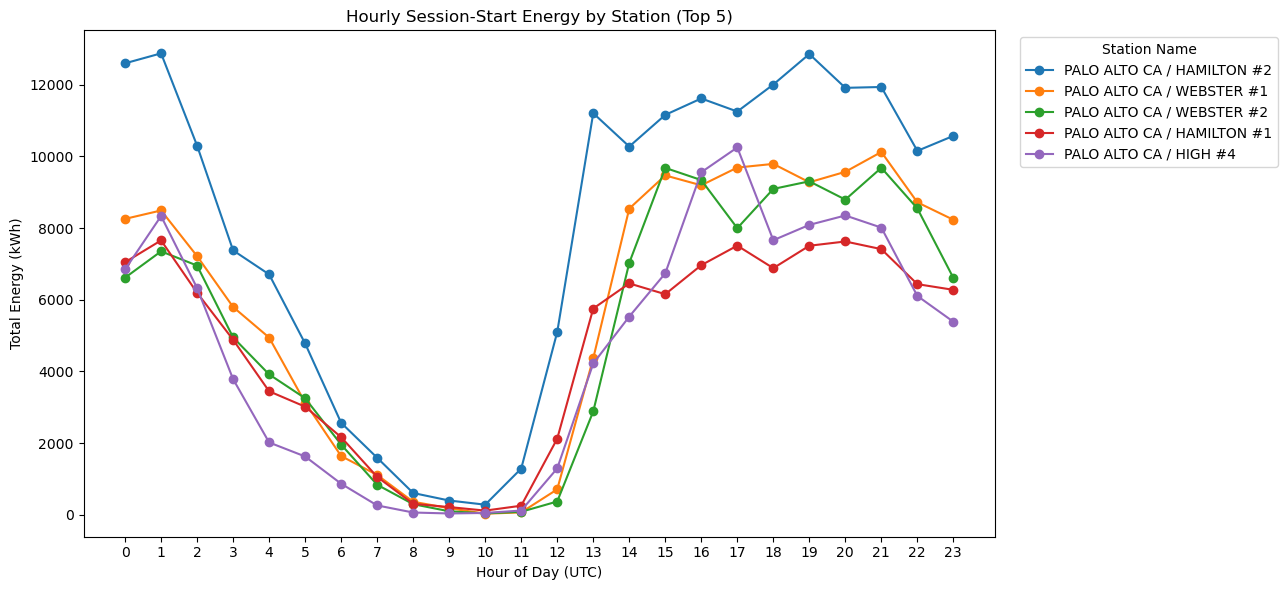

In [63]:

# Select the five stations with the highest total energy
top_5_stations = station_energy.head(5).index

# Extract hour of day
hourly_energy["Hour_Of_Day"] = hourly_energy["Hour"].dt.hour

# Calculate energy by station and hour of day
station_hour_pattern = (
    hourly_energy[hourly_energy["Station Name"].isin(top_5_stations)].groupby(["Station Name", "Hour_Of_Day"])["Energy (kWh)"].sum().reset_index())

# Plot each station as a separate line
plt.figure(figsize=(13, 6))
for station in top_5_stations:
    station_data = station_hour_pattern[station_hour_pattern["Station Name"] == station]
    plt.plot( station_data["Hour_Of_Day"],station_data["Energy (kWh)"],marker="o",label=station)

plt.title("Hourly Session-Start Energy by Station (Top 5)")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Total Energy (kWh)")
plt.xticks(range(24))
plt.legend(title="Station Name", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [64]:
print("Dataset shape:", df_time_clean.shape)

column_check = pd.DataFrame({"Column": df_time_clean.columns,"Data_Type": df_time_clean.dtypes.astype(str).values,
    "Non_Null_Count": df_time_clean.notna().sum().values,"Missing_Count": df_time_clean.isna().sum().values,
    "Missing_Percentage": (df_time_clean.isna().mean().values * 100).round(2)})

display(column_check)

Dataset shape: (259036, 40)


,Column,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage
0,Station Name,object,259036,0,0.00
1,MAC Address,object,259036,0,0.00
2,Org Name,object,259036,0,0.00
3,Start Date,datetime64[ns],259036,0,0.00
4,Start Time Zone,object,259036,0,0.00
5,End Date,datetime64[ns],259036,0,0.00
6,End Time Zone,object,259036,0,0.00
7,Transaction Date (Pacific Time),object,258905,131,0.05
8,Total Duration (hh:mm:ss),object,259036,0,0.00
9,Charging Time (hh:mm:ss),object,259036,0,0.00


In [65]:
# Sessions with exactly 0 minutes
zero_minute = df_time_clean[
    df_time_clean["Elapsed_UTC_Minutes"] == 0
]

# Sessions lasting more than 0 but less than 2 minutes
under_2_minutes = df_time_clean[
    (df_time_clean["Elapsed_UTC_Minutes"] > 0) &
    (df_time_clean["Elapsed_UTC_Minutes"] < 2)
]

# All sessions lasting less than 2 minutes, including zero
less_than_2 = df_time_clean[
    df_time_clean["Elapsed_UTC_Minutes"] < 2
]

print("Zero-minute sessions:", len(zero_minute))
print("Sessions between 0 and 2 minutes:", len(under_2_minutes))
print("Total sessions below 2 minutes:", len(less_than_2))

Zero-minute sessions: 0
Sessions between 0 and 2 minutes: 692
Total sessions below 2 minutes: 692


In [ ]:
evse_usage = (
    df_time_clean
    .dropna(subset=["EVSE ID"])
    .groupby("EVSE ID")
    .size()
    .reset_index(name="Total Sessions")
    .sort_values("Total Sessions", ascending=True)
)
display(evse_usage)

,EVSE ID,Total Sessions
41,5526211.0,1
43,5526231.0,1
46,5526281.0,1
48,5526771.0,1
45,5526271.0,1
38,5526171.0,2
44,5526261.0,2
39,5526181.0,3
50,5535441.0,4
42,5526221.0,4


## New Clean Pipeline 

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("EVChargingStationUsage.csv", low_memory=False)
print(df.shape)
display(df.head())

(259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


In [2]:
# clean text
text_cols = ["Station Name", "Port Type", "Plug Type", "Ended By", "Start Time Zone", "End Time Zone"]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

df["Station Name"] = (
    df["Station Name"]
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\s*#\s*", " #", regex=True)
)

In [6]:
# parse dates + durations  (this replaces total_td)
df["Start Date"] = pd.to_datetime(df["Start Date"], errors="coerce")
df["End Date"] = pd.to_datetime(df["End Date"], errors="coerce")
df["Transaction Date (Pacific Time)"] = pd.to_datetime(df["Transaction Date (Pacific Time)"], errors="coerce")

total_duration = pd.to_timedelta(df["Total Duration (hh:mm:ss)"], errors="coerce")
charging_duration = pd.to_timedelta(df["Charging Time (hh:mm:ss)"], errors="coerce")

In [7]:
# basic checks + cleaned dataset
invalid_time = (
    df["Start Date"].isna() |
    df["End Date"].isna() |
    (df["End Date"] <= df["Start Date"])
)

df = df.drop_duplicates().copy()

clean_mask = (
    df["Start Date"].notna() &
    df["End Date"].notna() &
    (df["End Date"] > df["Start Date"]) &
    df["Station Name"].notna()
)

df_clean = df[clean_mask].copy()

print("Invalid time rows:", invalid_time.sum())
print("Rows after duplicate removal:", len(df))
print("Rows in cleaned dataset:", len(df_clean))

Invalid time rows: 83
Rows after duplicate removal: 259411
Rows in cleaned dataset: 259328


In [8]:
# UTC conversion (fixed)
zone_map = {"PST": "Etc/GMT+8", "PDT": "Etc/GMT+7", "UTC": "UTC"}

df_clean["Start Time Zone"] = df_clean["Start Time Zone"].astype("string").str.upper()
df_clean["End Time Zone"] = df_clean["End Time Zone"].astype("string").str.upper()

# IMPORTANT: create UTC-typed columns
df_clean["Start_UTC"] = pd.Series(pd.NaT, index=df_clean.index, dtype="datetime64[ns, UTC]")
df_clean["End_UTC"] = pd.Series(pd.NaT, index=df_clean.index, dtype="datetime64[ns, UTC]")

for label, tz in zone_map.items():
    m1 = (df_clean["Start Time Zone"] == label) & df_clean["Start Date"].notna()
    df_clean.loc[m1, "Start_UTC"] = (
        df_clean.loc[m1, "Start Date"]
        .dt.tz_localize(tz)
        .dt.tz_convert("UTC")
    )

    m2 = (df_clean["End Time Zone"] == label) & df_clean["End Date"].notna()
    df_clean.loc[m2, "End_UTC"] = (
        df_clean.loc[m2, "End Date"]
        .dt.tz_localize(tz)
        .dt.tz_convert("UTC")
    )

df_clean["Elapsed_UTC_Minutes"] = (df_clean["End_UTC"] - df_clean["Start_UTC"]).dt.total_seconds() / 60

# recorded duration minutes
recorded_minutes = total_duration.loc[df_clean.index].dt.total_seconds() / 60
df_clean["UTC_Duration_Difference_Minutes"] = (df_clean["Elapsed_UTC_Minutes"] - recorded_minutes).abs()

display(df_clean[["Start Date","End Date","Start_UTC","End_UTC","Elapsed_UTC_Minutes","UTC_Duration_Difference_Minutes"]].head())

,Start Date,End Date,Start_UTC,End_UTC,Elapsed_UTC_Minutes,UTC_Duration_Difference_Minutes
0,2011-07-29 20:17:00,2011-07-29 23:20:00,2011-07-30 03:17:00+00:00,2011-07-30 06:20:00+00:00,183.0,0.533333
1,2011-07-30 00:00:00,2011-07-30 00:02:00,2011-07-30 07:00:00+00:00,2011-07-30 07:02:00+00:00,2.0,0.100000
2,2011-07-30 08:16:00,2011-07-30 12:34:00,2011-07-30 15:16:00+00:00,2011-07-30 19:34:00+00:00,258.0,0.466667
3,2011-07-30 14:51:00,2011-07-30 16:55:00,2011-07-30 21:51:00+00:00,2011-07-30 23:55:00+00:00,124.0,0.600000
4,2011-07-30 18:51:00,2011-07-30 20:03:00,2011-07-31 01:51:00+00:00,2011-07-31 03:03:00+00:00,72.0,0.600000


In [9]:
# final time-valid dataset
time_quality_mask = (
    df_clean["Start_UTC"].notna() &
    df_clean["End_UTC"].notna() &
    (df_clean["Elapsed_UTC_Minutes"] > 0) &
    ((df_clean["UTC_Duration_Difference_Minutes"].isna()) | (df_clean["UTC_Duration_Difference_Minutes"] <= 2))
)

df_time_clean = df_clean[time_quality_mask].copy()
print("Final rows for analysis:", len(df_time_clean))

Final rows for analysis: 259002


In [10]:
# H1) Split one charging session across hours
def split_session_into_hours(start_utc, end_utc):
    rows = []
    h = start_utc.floor("h")
    while h < end_utc:
        h_end = h + pd.Timedelta(hours=1)
        overlap_start = max(start_utc, h)
        overlap_end = min(end_utc, h_end)
        overlap_hours = (overlap_end - overlap_start).total_seconds() / 3600
        if overlap_hours > 0:
            rows.append((h, overlap_hours))
        h = h_end
    return rows

In [11]:
# H2) Build hourly station/user tables
station_rows = []
user_rows = []

for _, r in df_time_clean.iterrows():
    parts = split_session_into_hours(r["Start_UTC"], r["End_UTC"])
    total_h = sum(x[1] for x in parts)
    energy = r["Energy (kWh)"] if pd.notna(r["Energy (kWh)"]) else 0.0

    for hour, occ_h in parts:
        e_h = (energy * occ_h / total_h) if total_h > 0 else 0.0

        station_rows.append({
            "Station Name": r["Station Name"],
            "Hour": hour,
            "Energy (kWh)": e_h,
            "Occupied_Port_Hours": occ_h,
            "Session_Count": 1
        })

        if pd.notna(r["User ID"]) and str(r["User ID"]).strip() != "":
            user_rows.append({
                "User ID": str(r["User ID"]).strip(),
                "Hour": hour,
                "Energy (kWh)": e_h,
                "Occupied_Port_Hours": occ_h,
                "Session_Count": 1
            })

hourly_energy = pd.DataFrame(station_rows).groupby(
    ["Station Name", "Hour"], as_index=False
).sum()

hourly_user_usage = pd.DataFrame(user_rows).groupby(
    ["User ID", "Hour"], as_index=False
).sum()

print("hourly_energy rows:", len(hourly_energy))
print("hourly_user_usage rows:", len(hourly_user_usage))
display(hourly_energy.head())

hourly_energy rows: 653425
hourly_user_usage rows: 861442


,Station Name,Hour,Energy (kWh),Occupied_Port_Hours,Session_Count
0,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00+00:00,0.664281,0.183333,1
1,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00+00:00,0.966227,0.266667,1
2,PALO ALTO CA / BRYANT #1,2011-10-14 01:00:00+00:00,0.681748,0.183333,1
3,PALO ALTO CA / BRYANT #1,2011-10-14 02:00:00+00:00,3.718623,1.000000,1
4,PALO ALTO CA / BRYANT #1,2011-10-14 03:00:00+00:00,2.231174,0.600000,1


In [12]:
# H3) Add local-time features
hourly_energy["Hour_Local"] = hourly_energy["Hour"].dt.tz_convert("America/Los_Angeles")
hourly_energy["Hour_Of_Day"] = hourly_energy["Hour_Local"].dt.hour
hourly_energy["Weekday_Local"] = hourly_energy["Hour_Local"].dt.dayofweek

hourly_user_usage["Hour_Local"] = hourly_user_usage["Hour"].dt.tz_convert("America/Los_Angeles")
hourly_user_usage["Hour_Of_Day"] = hourly_user_usage["Hour_Local"].dt.hour
hourly_user_usage["Weekday_Local"] = hourly_user_usage["Hour_Local"].dt.dayofweek

display(hourly_energy.head())

/var/folders/v_/70wdhjs53ylbyj_44k3d8p4r0000gn/T/ipykernel_72724/1405607944.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hourly_energy["Weekday_Local"] = hourly_energy["Hour_Local"].dt.dayofweek
/var/folders/v_/70wdhjs53ylbyj_44k3d8p4r0000gn/T/ipykernel_72724/1405607944.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hourly_user_usage["Weekday_Local"] = hourly_user_usage["Hour_Local"].dt.dayofweek


,Station Name,Hour,Energy (kWh),Occupied_Port_Hours,Session_Count,Hour_Local,Hour_Of_Day,Weekday_Local
0,PALO ALTO CA / BRYANT #1,2011-10-13 19:00:00+00:00,0.664281,0.183333,1,2011-10-13 12:00:00-07:00,12,3
1,PALO ALTO CA / BRYANT #1,2011-10-13 20:00:00+00:00,0.966227,0.266667,1,2011-10-13 13:00:00-07:00,13,3
2,PALO ALTO CA / BRYANT #1,2011-10-14 01:00:00+00:00,0.681748,0.183333,1,2011-10-13 18:00:00-07:00,18,3
3,PALO ALTO CA / BRYANT #1,2011-10-14 02:00:00+00:00,3.718623,1.000000,1,2011-10-13 19:00:00-07:00,19,3
4,PALO ALTO CA / BRYANT #1,2011-10-14 03:00:00+00:00,2.231174,0.600000,1,2011-10-13 20:00:00-07:00,20,3
